In [9]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import os
os.chdir('/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO')
CWD_PATH = os.getcwd()
print(CWD_PATH)

/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO


In [11]:
import cv2
import numpy as np
import csv
from pathlib import Path
import matplotlib.pyplot as plt
import os

In [12]:
cars_path = '/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO/videos/buses.mp4'
rolling_ball_path ='/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO/videos/rolling_ball.mp4'


**Task 1. Optical flow, sparse and dense**

In [ ]:

##############################################
# CONFIGURATION
##############################################

VIDEO_PATH = cars_path
OUTPUT_DIR = Path("videos/optical_flow_results")
OUTPUT_DIR.mkdir(exist_ok=True)

MAX_CORNERS = 400
MIN_DISTANCE = 8
MIN_TRACKED_POINTS = 100

# Brightness experiment settings
BRIGHTNESS_FRAME_INDEX = 30
BRIGHTNESS_FRAME_GAP = 5
BRIGHTNESS_OFFSET = 60


##############################################
# HELPER FUNCTIONS
##############################################

def create_writer(filename, fps, size):
    writer = cv2.VideoWriter(
        str(OUTPUT_DIR / filename),
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        size
    )
    if not writer.isOpened():
        raise RuntimeError(f"Could not create {filename}")
    return writer


def detect_corners(gray, mask=None):
    return cv2.goodFeaturesToTrack(
        gray,
        maxCorners=MAX_CORNERS,
        qualityLevel=0.01,
        minDistance=MIN_DISTANCE,
        blockSize=7,
        mask=mask,
        useHarrisDetector=False
    )


def calculate_farneback(gray1, gray2):
    flow = cv2.calcOpticalFlowFarneback(
        gray1,
        gray2,
        None,
        0.5,       # Pyramid scale
        4,         # Pyramid levels
        21,        # Window size
        3,         # Iterations
        5,         # Polynomial neighbourhood
        1.2,       # Gaussian standard deviation
        0
    )

    magnitude, angle = cv2.cartToPolar(
        flow[..., 0],
        flow[..., 1],
        angleInDegrees=True
    )

    hsv = np.zeros(
        (gray1.shape[0], gray1.shape[1], 3),
        dtype=np.uint8
    )

    # Hue represents direction.
    hsv[..., 0] = (angle / 2).astype(np.uint8)

    # Full saturation.
    hsv[..., 1] = 255

    # Value represents relative motion magnitude.
    hsv[..., 2] = cv2.normalize(
        magnitude,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    ).astype(np.uint8)

    flow_image = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    return flow, magnitude, flow_image


def add_label(image, text, position=(10, 30)):
    cv2.putText(
        image,
        text,
        position,
        cv2.FONT_HERSHEY_SIMPLEX,
        0.65,
        (255, 255, 255),
        2,
        cv2.LINE_AA
    )



In [ ]:
##############################################
# LOAD VIDEO
##############################################

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise FileNotFoundError(
        f"Cannot open video: {VIDEO_PATH}"
    )

fps = cap.get(cv2.CAP_PROP_FPS)
if fps <= 0:
    fps = 25.0

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

ret, first_frame = cap.read()

if not ret:
    cap.release()
    raise ValueError("Could not read the video.")

lk_writer = create_writer(
    "lk_motion_trails.mp4", fps, (width, height)
)

farneback_writer = create_writer(
    "farneback_hsv.mp4", fps, (width, height)
)

side_writer = create_writer(
    "side_by_side.mp4", fps, (width * 2, height)
)


In [ ]:
##############################################
# SHI-TOMASI + LUCAS-KANADE
##############################################

previous_gray = cv2.cvtColor(
    first_frame, cv2.COLOR_BGR2GRAY
)

previous_points = detect_corners(previous_gray)

# Persistent canvas for motion trails.
trail_canvas = np.zeros_like(first_frame)

lk_params = dict(
    winSize=(21, 21),
    maxLevel=3,
    criteria=(
        cv2.TERM_CRITERIA_EPS |
        cv2.TERM_CRITERIA_COUNT,
        30,
        0.01
    )
)

# Save the initial feature points.
initial_display = first_frame.copy()

if previous_points is not None:
    for point in previous_points.reshape(-1, 2):
        x, y = point.astype(int)
        cv2.circle(
            initial_display, (x, y), 3, (0, 0, 255), -1
        )

add_label(initial_display, "Shi-Tomasi initial corners")
lk_writer.write(initial_display)

# Initial Farneback frame has no preceding pair.
farneback_writer.write(np.zeros_like(first_frame))
side_writer.write(
    np.hstack([
        initial_display,
        np.zeros_like(first_frame)
    ])
)

frame_index = 0

with open(
    OUTPUT_DIR / "lk_tracking_log.csv",
    "w",
    newline="",
    encoding="utf-8"
) as log_file:

    log_writer = csv.writer(log_file)
    log_writer.writerow([
        "Frame",
        "Tracked_Points",
        "Mean_Displacement_Pixels"
    ])

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        frame_index += 1

        current_gray = cv2.cvtColor(
            frame, cv2.COLOR_BGR2GRAY
        )

        display = frame.copy()

        good_old = np.empty((0, 2), dtype=np.float32)
        good_new = np.empty((0, 2), dtype=np.float32)

        # Track the existing feature points.
        if previous_points is not None and len(previous_points) > 0:

            next_points, status, errors = (
                cv2.calcOpticalFlowPyrLK(
                    previous_gray,
                    current_gray,
                    previous_points,
                    None,
                    **lk_params
                )
            )

            if next_points is not None and status is not None:

                old_all = previous_points.reshape(-1, 2)
                new_all = next_points.reshape(-1, 2)

                valid = status.ravel().astype(bool)

                # Remove points that have left the image.
                valid &= (
                    (new_all[:, 0] >= 0) &
                    (new_all[:, 0] < width) &
                    (new_all[:, 1] >= 0) &
                    (new_all[:, 1] < height)
                )

                good_old = old_all[valid]
                good_new = new_all[valid]

                for old, new in zip(good_old, good_new):

                    x_old, y_old = np.round(old).astype(int)
                    x_new, y_new = np.round(new).astype(int)

                    # Draw motion trails.
                    cv2.line(
                        trail_canvas,
                        (x_old, y_old),
                        (x_new, y_new),
                        (0, 255, 0),
                        2,
                        cv2.LINE_AA
                    )

                    # Draw current tracked points.
                    cv2.circle(
                        display,
                        (x_new, y_new),
                        3,
                        (0, 0, 255),
                        -1
                    )

        # Calculate average displacement of successful tracks.
        if len(good_new) > 0:
            displacement = np.linalg.norm(
                good_new - good_old, axis=1
            )
            mean_displacement = float(np.mean(displacement))
        else:
            mean_displacement = 0.0

        log_writer.writerow([
            frame_index,
            len(good_new),
            round(mean_displacement, 4)
        ])

        # Re-detect corners when too few points remain.
        if len(good_new) < MIN_TRACKED_POINTS:

            new_points = detect_corners(current_gray)

            if new_points is not None:

                # Avoid adding new points too close to active tracks.
                mask = np.full(
                    (height, width), 255, dtype=np.uint8
                )

                for x, y in np.round(good_new).astype(int):
                    cv2.circle(
                        mask,
                        (x, y),
                        MIN_DISTANCE,
                        0,
                        -1
                    )

                additional_points = detect_corners(
                    current_gray, mask
                )

                active_points = good_new.reshape(-1, 1, 2)

                if additional_points is not None:
                    previous_points = np.vstack([
                        active_points,
                        additional_points
                    ]).astype(np.float32)
                elif len(active_points) > 0:
                    previous_points = active_points.astype(
                        np.float32
                    )
                else:
                    previous_points = new_points.astype(
                        np.float32
                    )

            elif len(good_new) > 0:
                previous_points = good_new.reshape(
                    -1, 1, 2
                ).astype(np.float32)

            else:
                previous_points = None

        else:
            previous_points = good_new.reshape(
                -1, 1, 2
            ).astype(np.float32)

        # Overlay trails on the current frame.
        trail_display = cv2.add(display, trail_canvas)

        add_label(
            trail_display,
            f"Lucas-Kanade | Tracked: {len(good_new)}"
        )

        lk_writer.write(trail_display)

In [ ]:
##############################################
#  SHI-TOMASI + LUCAS-KANADE
##############################################

previous_gray = cv2.cvtColor(
    first_frame, cv2.COLOR_BGR2GRAY
)

previous_points = detect_corners(previous_gray)

# Persistent canvas for motion trails.
trail_canvas = np.zeros_like(first_frame)

lk_params = dict(
    winSize=(21, 21),
    maxLevel=3,
    criteria=(
        cv2.TERM_CRITERIA_EPS |
        cv2.TERM_CRITERIA_COUNT,
        30,
        0.01
    )
)

# Save the initial feature points.
initial_display = first_frame.copy()

if previous_points is not None:
    for point in previous_points.reshape(-1, 2):
        x, y = point.astype(int)
        cv2.circle(
            initial_display, (x, y), 3, (0, 0, 255), -1
        )

add_label(initial_display, "Shi-Tomasi initial corners")
lk_writer.write(initial_display)

# Initial Farneback frame has no preceding pair.
farneback_writer.write(np.zeros_like(first_frame))
side_writer.write(
    np.hstack([
        initial_display,
        np.zeros_like(first_frame)
    ])
)

frame_index = 0

with open(
    OUTPUT_DIR / "lk_tracking_log.csv",
    "w",
    newline="",
    encoding="utf-8"
) as log_file:

    log_writer = csv.writer(log_file)
    log_writer.writerow([
        "Frame",
        "Tracked_Points",
        "Mean_Displacement_Pixels"
    ])

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        frame_index += 1

        current_gray = cv2.cvtColor(
            frame, cv2.COLOR_BGR2GRAY
        )

        display = frame.copy()

        good_old = np.empty((0, 2), dtype=np.float32)
        good_new = np.empty((0, 2), dtype=np.float32)

        # Track the existing feature points.
        if previous_points is not None and len(previous_points) > 0:

            next_points, status, errors = (
                cv2.calcOpticalFlowPyrLK(
                    previous_gray,
                    current_gray,
                    previous_points,
                    None,
                    **lk_params
                )
            )

            if next_points is not None and status is not None:

                old_all = previous_points.reshape(-1, 2)
                new_all = next_points.reshape(-1, 2)

                valid = status.ravel().astype(bool)

                # Remove points that have left the image.
                valid &= (
                    (new_all[:, 0] >= 0) &
                    (new_all[:, 0] < width) &
                    (new_all[:, 1] >= 0) &
                    (new_all[:, 1] < height)
                )

                good_old = old_all[valid]
                good_new = new_all[valid]

                for old, new in zip(good_old, good_new):

                    x_old, y_old = np.round(old).astype(int)
                    x_new, y_new = np.round(new).astype(int)

                    # Draw motion trails.
                    cv2.line(
                        trail_canvas,
                        (x_old, y_old),
                        (x_new, y_new),
                        (0, 255, 0),
                        2,
                        cv2.LINE_AA
                    )

                    # Draw current tracked points.
                    cv2.circle(
                        display,
                        (x_new, y_new),
                        3,
                        (0, 0, 255),
                        -1
                    )

        # Calculate average displacement of successful tracks.
        if len(good_new) > 0:
            displacement = np.linalg.norm(
                good_new - good_old, axis=1
            )
            mean_displacement = float(np.mean(displacement))
        else:
            mean_displacement = 0.0

        log_writer.writerow([
            frame_index,
            len(good_new),
            round(mean_displacement, 4)
        ])

        # Re-detect corners when too few points remain.
        if len(good_new) < MIN_TRACKED_POINTS:

            new_points = detect_corners(current_gray)

            if new_points is not None:

                # Avoid adding new points too close to active tracks.
                mask = np.full(
                    (height, width), 255, dtype=np.uint8
                )

                for x, y in np.round(good_new).astype(int):
                    cv2.circle(
                        mask,
                        (x, y),
                        MIN_DISTANCE,
                        0,
                        -1
                    )

                additional_points = detect_corners(
                    current_gray, mask
                )

                active_points = good_new.reshape(-1, 1, 2)

                if additional_points is not None:
                    previous_points = np.vstack([
                        active_points,
                        additional_points
                    ]).astype(np.float32)
                elif len(active_points) > 0:
                    previous_points = active_points.astype(
                        np.float32
                    )
                else:
                    previous_points = new_points.astype(
                        np.float32
                    )

            elif len(good_new) > 0:
                previous_points = good_new.reshape(
                    -1, 1, 2
                ).astype(np.float32)

            else:
                previous_points = None

        else:
            previous_points = good_new.reshape(
                -1, 1, 2
            ).astype(np.float32)

        # Overlay trails on the current frame.
        trail_display = cv2.add(display, trail_canvas)

        add_label(
            trail_display,
            f"Lucas-Kanade | Tracked: {len(good_new)}"
        )

        lk_writer.write(trail_display)

       ##############################################
        # DENSE FARNEBACK OPTICAL FLOW
       ##############################################

        flow, magnitude, flow_image = calculate_farneback(
            previous_gray,
            current_gray
        )

        add_label(
            flow_image,
            "Farneback HSV: Hue=Direction, Value=Magnitude"
        )

        farneback_writer.write(flow_image)

        # Side-by-side comparison.
        side_by_side = np.hstack([
            trail_display,
            flow_image
        ])

        side_writer.write(side_by_side)

        previous_gray = current_gray.copy()


cap.release()
lk_writer.release()
farneback_writer.release()
side_writer.release()

In [ ]:

##############################################
# BRIGHTNESS-CONSTANCY FAILURE EXPERIMENT
##############################################

def read_frame_at(path, target_index):
    video = cv2.VideoCapture(path)

    if not video.isOpened():
        raise FileNotFoundError(path)

    video.set(cv2.CAP_PROP_POS_FRAMES, target_index)
    ret, frame = video.read()
    video.release()

    return frame if ret else None


frame_a = read_frame_at(
    VIDEO_PATH, BRIGHTNESS_FRAME_INDEX
)

frame_b = read_frame_at(
    VIDEO_PATH,
    BRIGHTNESS_FRAME_INDEX + BRIGHTNESS_FRAME_GAP
)

if frame_a is None or frame_b is None:
    # Fallback for short videos.
    frame_a = first_frame.copy()
    frame_b = first_frame.copy()

gray_a = cv2.cvtColor(frame_a, cv2.COLOR_BGR2GRAY)
gray_b = cv2.cvtColor(frame_b, cv2.COLOR_BGR2GRAY)

# Original frame pair.
normal_flow, normal_magnitude, normal_vis = (
    calculate_farneback(gray_a, gray_b)
)

# Artificially brighten frame B without changing its geometry.
bright_frame_b = cv2.convertScaleAbs(
    frame_b,
    alpha=1.0,
    beta=BRIGHTNESS_OFFSET
)

gray_bright = cv2.cvtColor(
    bright_frame_b, cv2.COLOR_BGR2GRAY
)

broken_flow, broken_magnitude, broken_vis = (
    calculate_farneback(gray_a, gray_bright)
)

# Label comparison panels.
add_label(frame_a, "Frame A")
add_label(frame_b, "Frame B: Original")
add_label(bright_frame_b, "Frame B: Brightened")
add_label(normal_vis, "Flow: Original Pair")
add_label(broken_vis, "Flow: Brightness Changed")

# Save the original pair and flow comparison.
top_row = np.hstack([frame_a, frame_b])
bottom_row = np.hstack([normal_vis, broken_vis])

comparison = np.vstack([top_row, bottom_row])

cv2.imwrite(
    str(OUTPUT_DIR / "brightness_failure_comparison.jpg"),
    comparison
)

cv2.imwrite(
    str(OUTPUT_DIR / "brightness_altered_frame.jpg"),
    bright_frame_b
)


##############################################
# FINISHED
##############################################

print("\nProcessing completed successfully.")
print("Results saved in:", OUTPUT_DIR.resolve())
print("1. lk_motion_trails.mp4")
print("2. farneback_hsv.mp4")
print("3. side_by_side.mp4")
print("4. brightness_failure_comparison.jpg")
print("5. brightness_altered_frame.jpg")
print("6. lk_tracking_log.csv")



Processing completed successfully.
Results saved in: /content/drive/MyDrive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO/videos/optical_flow_results
1. lk_motion_trails.mp4
2. farneback_hsv.mp4
3. side_by_side.mp4
4. brightness_failure_comparison.jpg
5. brightness_altered_frame.jpg
6. lk_tracking_log.csv


**Task 2. Track through occlusion with a Kalman filter**

Frame size       : 360 x 640
Requested ROI    : (140, 260, 80, 80)
Tracker object   : < cv2.legacy.TrackerCSRT 0x785b5a684850>
Tracker initialised (CSRT) on ROI (140, 260, 80, 80) (init returned True)
VideoWriter opened with codec: mp4v
CSV saved: videos/kalman_results/tracking_results.csv


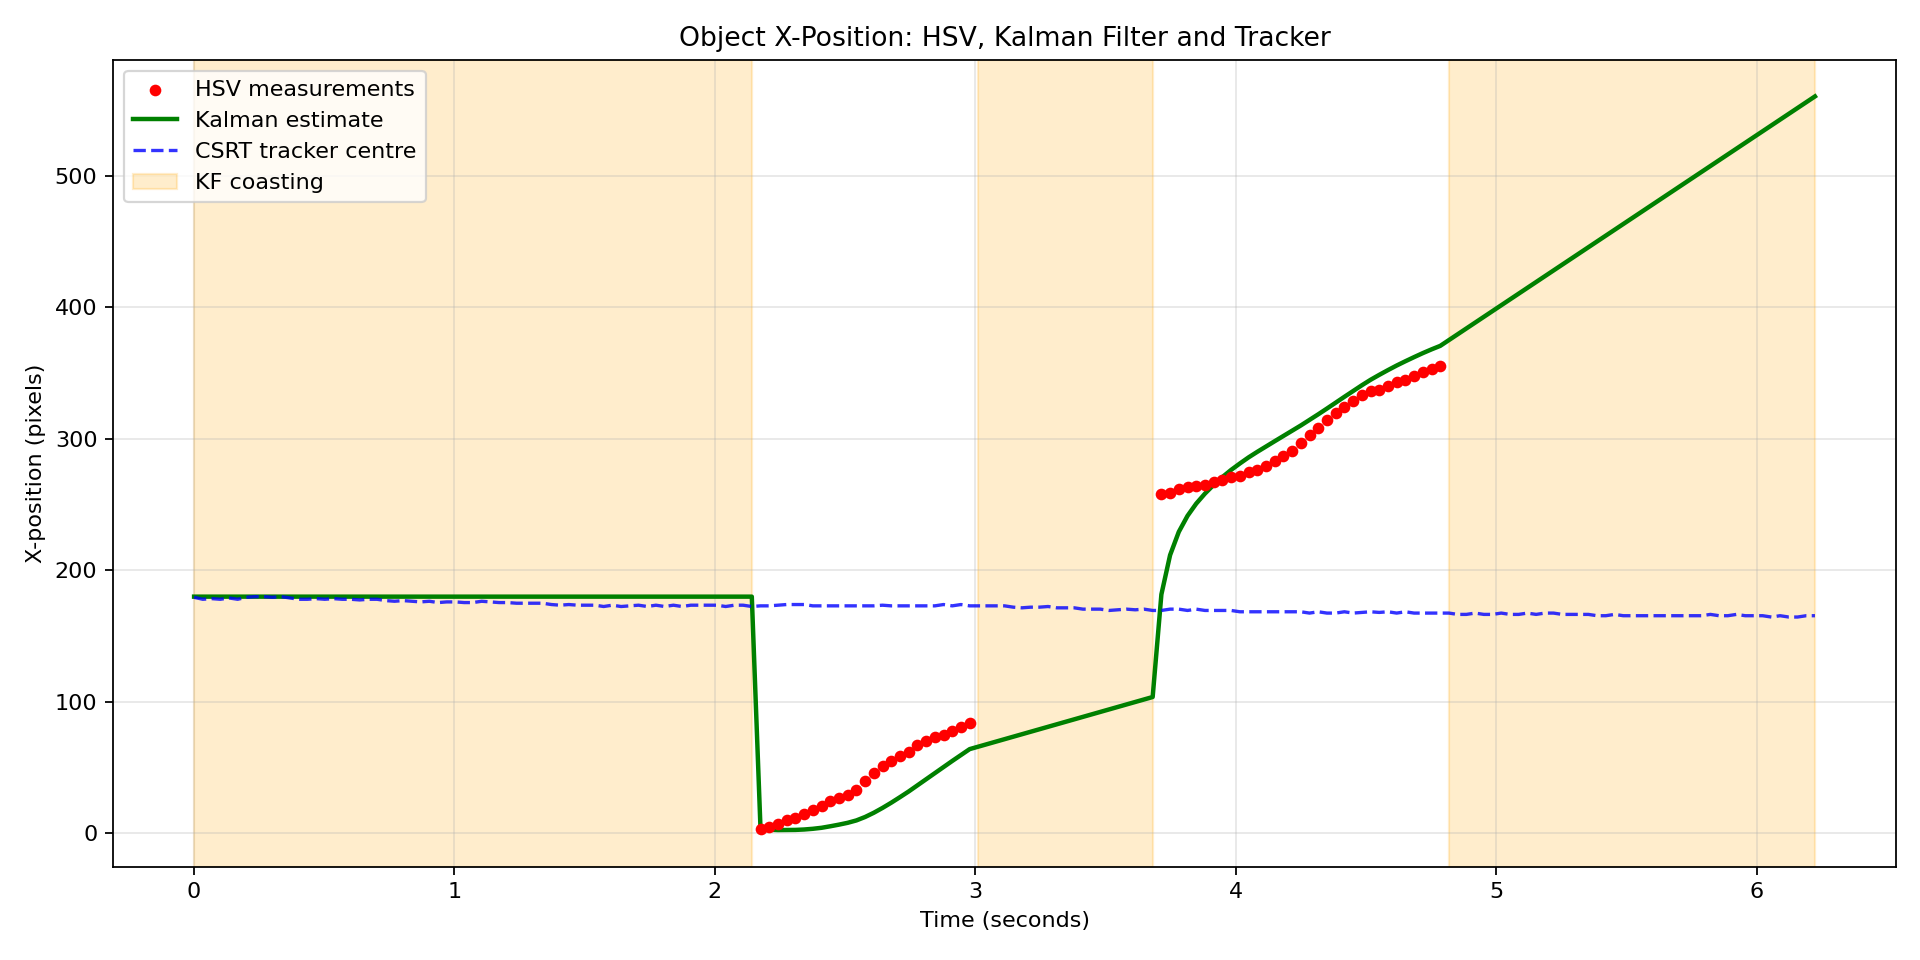


Processing complete.
Output folder  : /content/drive/MyDrive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO/videos/kalman_results
Annotated video: annotated_tracking.mp4
Position plot  : x_position_plot.png
CSV results    : tracking_results.csv


In [ ]:
##############################################
# COLAB SETUP
##############################################
!pip install -q opencv-contrib-python

import cv2
import csv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Video, Image, display

##############################################
# CONFIGURATION
##############################################

VIDEO_PATH = "videos/rolling_ball.mp4"

OUTPUT_DIR = Path("videos/kalman_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# "CSRT" or "KCF"
TRACKER_TYPE = "CSRT"

# Kalman tuning parameters
PROCESS_NOISE_ACCEL_STD = 80.0
MEASUREMENT_NOISE_STD   = 15.0

# Use None to rely on natural occlusion in the video.
FORCE_OCCLUSION = None       # e.g. (100, 140)

# Ignore very small colour blobs
MIN_CONTOUR_AREA = 100

##############################################
# HARD-CODED HSV RANGE  (adjust for your ball's colour)
# Default: generous red range. Tune with the picker below.
##############################################
lower_hsv = np.array([0,   100, 100], dtype=np.uint8)
upper_hsv = np.array([179, 255, 255], dtype=np.uint8)

##############################################
# HARD-CODED INITIAL ROI  (x, y, w, h)
# Frame is 360 wide × 640 tall, so:
#   x + w <= 360
#   y + h <= 640
##############################################
INITIAL_ROI = (140, 260, 80, 80)     # (x, y, w, h)


##############################################
# HELPER FUNCTIONS
##############################################

def create_tracker(tracker_type):
    """
    Return a tracker that initialises reliably.

    In OpenCV >=4.13 the non-legacy CSRT/KCF init() returns None on
    success (not True), which breaks `if not tracker.init(...)`.
    Prefer the legacy API, which returns proper True/False.
    """
    name = tracker_type.upper()

    legacy = getattr(cv2, "legacy", None)
    if legacy is not None:
        if name == "CSRT" and hasattr(legacy, "TrackerCSRT_create"):
            return legacy.TrackerCSRT_create()
        if name == "KCF" and hasattr(legacy, "TrackerKCF_create"):
            return legacy.TrackerKCF_create()

    # Fallback: modern API.
    if name == "CSRT" and hasattr(cv2, "TrackerCSRT_create"):
        return cv2.TrackerCSRT_create()
    if name == "KCF" and hasattr(cv2, "TrackerKCF_create"):
        return cv2.TrackerKCF_create()

    raise RuntimeError(
        f"{name} tracker is unavailable. Install opencv-contrib-python."
    )


def detect_largest_colour_object(frame, lower, upper):
    """
    Detect the largest HSV colour contour.
    Return centroid (x, y), bounding box and mask.
    Return None for the centroid when no suitable contour exists.
    """
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, lower, upper)

    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return None, None, mask

    contour = max(contours, key=cv2.contourArea)
    if cv2.contourArea(contour) < MIN_CONTOUR_AREA:
        return None, None, mask

    moments = cv2.moments(contour)
    if moments["m00"] == 0:
        return None, None, mask

    cx = int(moments["m10"] / moments["m00"])
    cy = int(moments["m01"] / moments["m00"])

    bbox = cv2.boundingRect(contour)
    return (cx, cy), bbox, mask


##############################################
# INTERACTIVE HSV PICKER VIA ipywidgets
# Uncomment and run to tune lower_hsv / upper_hsv from frame 1.
##############################################
"""
import ipywidgets as widgets

_cap = cv2.VideoCapture(VIDEO_PATH)
_ret, _frame = _cap.read()
_cap.release()
_hsv = cv2.cvtColor(_frame, cv2.COLOR_BGR2HSV)

def _pick(hlo, hhi, slo, shi, vlo, vhi):
    _lower = np.array([hlo, slo, vlo], dtype=np.uint8)
    _upper = np.array([hhi, shi, vhi], dtype=np.uint8)
    _mask = cv2.inRange(_hsv, _lower, _upper)
    _overlay = cv2.bitwise_and(_frame, _frame, mask=_mask)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(cv2.cvtColor(_frame, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(cv2.cvtColor(_overlay, cv2.COLOR_BGR2RGB))
    axes[1].set_title("HSV mask"); axes[1].axis("off")
    plt.tight_layout(); plt.show()

    print(f"lower_hsv = np.array([{hlo}, {slo}, {vlo}], dtype=np.uint8)")
    print(f"upper_hsv = np.array([{hhi}, {shi}, {vhi}], dtype=np.uint8)")

widgets.interact(
    _pick,
    hlo=widgets.IntSlider(0,   0, 179, 1),
    hhi=widgets.IntSlider(179, 0, 179, 1),
    slo=widgets.IntSlider(70,  0, 255, 1),
    shi=widgets.IntSlider(255, 0, 255, 1),
    vlo=widgets.IntSlider(50,  0, 255, 1),
    vhi=widgets.IntSlider(255, 0, 255, 1),
)
"""


##############################################
# CONSTANT-VELOCITY KALMAN FILTER
# State: [x, y, vx, vy];  Measurement: [x, y]
##############################################

class ConstantVelocityKalman:

    def __init__(
        self,
        x,
        y,
        fps,
        process_accel_std=80.0,
        measurement_std=15.0
    ):
        self.dt = 1.0 / max(fps, 1e-6)

        self.state = np.array(
            [[float(x)], [float(y)], [0.0], [0.0]],
            dtype=np.float64
        )

        dt = self.dt

        self.F = np.array([
            [1, 0, dt, 0],
            [0, 1, 0, dt],
            [0, 0, 1, 0],
            [0, 0, 0, 1]
        ], dtype=np.float64)

        self.H = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0]
        ], dtype=np.float64)

        self.P = np.diag([
            25.0**2,
            25.0**2,
            200.0**2,
            200.0**2
        ])

        q = process_accel_std**2

        self.Q = q * np.array([
            [dt**4 / 4, 0, dt**3 / 2, 0],
            [0, dt**4 / 4, 0, dt**3 / 2],
            [dt**3 / 2, 0, dt**2, 0],
            [0, dt**3 / 2, 0, dt**2]
        ], dtype=np.float64)

        self.R = np.eye(2) * measurement_std**2
        self.I = np.eye(4)

    def predict(self):
        self.state = self.F @ self.state
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.position()

    def update(self, measurement):
        z = np.array(
            [[float(measurement[0])],
             [float(measurement[1])]],
            dtype=np.float64
        )

        innovation = z - self.H @ self.state
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)

        self.state = self.state + K @ innovation

        A = self.I - K @ self.H
        self.P = A @ self.P @ A.T + K @ self.R @ K.T

    def position(self):
        return (
            float(self.state[0, 0]),
            float(self.state[1, 0])
        )


##############################################
# TRACKER INITIALISATION (ROI validated + legacy API)
##############################################

cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise FileNotFoundError(VIDEO_PATH)

fps = cap.get(cv2.CAP_PROP_FPS)
if fps <= 0:
    fps = 25.0

width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

ret, first_frame = cap.read()
if not ret:
    cap.release()
    raise ValueError("Could not read the first frame.")

# Validate ROI
x, y, w, h = map(int, INITIAL_ROI)

print(f"Frame size       : {width} x {height}")
print(f"Requested ROI    : {(x, y, w, h)}")

if not (0 <= x < width and 0 <= y < height):
    cap.release()
    raise ValueError(
        f"ROI origin ({x},{y}) outside {width}x{height} frame."
    )
if w <= 0 or h <= 0:
    cap.release()
    raise ValueError(f"ROI size must be positive, got ({w}x{h}).")
if x + w > width or y + h > height:
    cap.release()
    raise ValueError(
        f"ROI ({x},{y},{w},{h}) extends past frame edge "
        f"({width}x{height}). Need x+w<={width} and y+h<={height}."
    )

roi = (x, y, w, h)
initial_centre = (x + w / 2.0, y + h / 2.0)

# Kalman
kalman = ConstantVelocityKalman(
    initial_centre[0],
    initial_centre[1],
    fps,
    PROCESS_NOISE_ACCEL_STD,
    MEASUREMENT_NOISE_STD
)

# Tracker
tracker = create_tracker(TRACKER_TYPE)
print(f"Tracker object   : {tracker!r}")

init_result = tracker.init(first_frame, roi)

# Legacy API returns True/False. Modern 4.13+ API returns None on
# success. Treat only an explicit False as failure.
if init_result is False:
    cap.release()
    raise RuntimeError(
        f"{TRACKER_TYPE}.init() failed on ROI {roi} "
        f"for a {width}x{height} frame."
    )

print(f"Tracker initialised ({TRACKER_TYPE}) on ROI {roi} "
      f"(init returned {init_result!r})")


##############################################
# Video writer (Colab-safe with fallback codec)
##############################################
output_video_path = OUTPUT_DIR / "annotated_tracking.mp4"

def _make_writer(path, fps, size):
    for fourcc_str in ("mp4v", "avc1", "XVID"):
        fourcc = cv2.VideoWriter_fourcc(*fourcc_str)
        w_ = cv2.VideoWriter(str(path), fourcc, fps, size)
        if w_.isOpened():
            print(f"VideoWriter opened with codec: {fourcc_str}")
            return w_
        w_.release()
    raise RuntimeError("Could not create annotated video with any codec.")

writer = _make_writer(output_video_path, fps, (width, height))

# Rewind and process every frame consistently.
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

frame_index = 0
records = []


##############################################
# MAIN PROCESSING LOOP  (headless)
##############################################

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame_index += 1

    measurement, detection_bbox, mask = detect_largest_colour_object(
        frame, lower_hsv, upper_hsv
    )

    forced_occlusion = (
        FORCE_OCCLUSION is not None
        and FORCE_OCCLUSION[0] <= frame_index <= FORCE_OCCLUSION[1]
    )
    if forced_occlusion:
        measurement = None

    # Predict every frame.
    kalman.predict()

    if measurement is not None:
        mx, my = measurement
        cv2.circle(frame, (mx, my), 7, (0, 0, 255), -1)
        cv2.putText(
            frame, "HSV measurement", (mx + 8, my - 8),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2
        )
        kalman.update(measurement)
    else:
        cv2.putText(
            frame, "NO HSV DETECTION - KF COASTING",
            (10, 65),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 165, 255), 2
        )

    kf_x, kf_y = kalman.position()
    kx, ky = int(round(kf_x)), int(round(kf_y))

    cv2.circle(frame, (kx, ky), 7, (0, 255, 0), 2)
    cv2.putText(
        frame, "Kalman estimate", (kx + 8, ky + 18),
        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2
    )

    #Tracker update (robust to OpenCV 4.14 quirks)
    update_result = tracker.update(frame)

    if isinstance(update_result, tuple) and len(update_result) == 2:
        tracker_ok, tracker_bbox = update_result
        tracker_ok = bool(tracker_ok) and tracker_bbox is not None
    else:
        # Fallback: some builds return a bare bbox or None.
        tracker_ok = update_result is not None and update_result is not False
        tracker_bbox = update_result if tracker_ok else (0, 0, 0, 0)

    if tracker_ok:
        tx, ty, tw, th = map(int, tracker_bbox)
        cv2.rectangle(
            frame, (tx, ty), (tx + tw, ty + th),
            (255, 0, 0), 2
        )
        cv2.putText(
            frame, TRACKER_TYPE,
            (tx, max(20, ty - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2
        )
    else:
        cv2.putText(
            frame, f"{TRACKER_TYPE}: TRACK LOST",
            (10, 95),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2
        )

    is_coasting = measurement is None

    cv2.putText(
        frame, f"Frame: {frame_index}",
        (10, 30),
        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2
    )

    writer.write(frame)

    records.append({
        "frame": frame_index,
        "time_seconds": (frame_index - 1) / fps,
        "measurement_x": (
            measurement[0] if measurement is not None else np.nan
        ),
        "measurement_y": (
            measurement[1] if measurement is not None else np.nan
        ),
        "estimate_x": kf_x,
        "estimate_y": kf_y,
        "coasting": is_coasting,
        "tracker_success": bool(tracker_ok),
        "tracker_x": (
            tracker_bbox[0] + tracker_bbox[2] / 2
            if tracker_ok else np.nan
        )
    })

cap.release()
writer.release()


##############################################
# SAVE CSV RESULTS
##############################################

csv_path = OUTPUT_DIR / "tracking_results.csv"

if records:
    with open(csv_path, "w", newline="", encoding="utf-8") as file:
        fieldnames = list(records[0].keys())
        csv_writer = csv.DictWriter(file, fieldnames=fieldnames)
        csv_writer.writeheader()
        csv_writer.writerows(records)
    print(f"CSV saved: {csv_path}")
else:
    print("No records to write.")


##############################################
# PLOT X-POSITION OVER TIME
##############################################

if records:
    times          = np.array([r["time_seconds"] for r in records])
    measurements_x = np.array([r["measurement_x"] for r in records])
    estimates_x    = np.array([r["estimate_x"]    for r in records])
    tracker_x      = np.array([r["tracker_x"]     for r in records])
    coasting       = np.array([r["coasting"]      for r in records],
                              dtype=bool)

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.scatter(
        times, measurements_x,
        s=18, color="red",
        label="HSV measurements", zorder=3
    )
    ax.plot(
        times, estimates_x,
        color="green", linewidth=2,
        label="Kalman estimate"
    )
    ax.plot(
        times, tracker_x,
        color="blue", linestyle="--", alpha=0.8,
        label=f"{TRACKER_TYPE} tracker centre"
    )

    if coasting.any():
        padded_prev = np.r_[False, coasting[:-1]]
        padded_next = np.r_[coasting[1:], False]
        starts = np.where(coasting & ~padded_prev)[0]
        ends   = np.where(coasting & ~padded_next)[0]

        for i, (start, end) in enumerate(zip(starts, ends)):
            ax.axvspan(
                times[start], times[end],
                color="orange", alpha=0.2,
                label="KF coasting" if i == 0 else None
            )

    ax.set_title("Object X-Position: HSV, Kalman Filter and Tracker")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("X-position (pixels)")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()

    plot_path = OUTPUT_DIR / "x_position_plot.png"
    fig.savefig(plot_path, dpi=160)
    plt.close(fig)

    display(Image(filename=str(plot_path)))


##############################################
# DISPLAY ANNOTATED VIDEO INLINE
##############################################

print("\nProcessing complete.")
print("Output folder  :", OUTPUT_DIR.resolve())
print("Annotated video:", output_video_path.name)
print("Position plot  : x_position_plot.png")
print("CSV results    : tracking_results.csv")

if output_video_path.exists():
    display(Video(str(output_video_path), embed=True))

**what does each approach do when the object disappears?**</br>
When the object disappears, HSV colour detection simply stops reporting. It evaluates each frame independently, and so as soon as the coloured pixels no longer match the thresholded range, detect_largest_colour_object returns None and no measurement is produced. There is no memory, no extrapolation, and no guess about where the object might be. It signals that the object is not visible.

The Kalman filter keeps going. Because it carries a constant-velocity motion model, it continues to call predict() on every frame even without a measurement, propagating the state forward using the last known velocity and inflating its covariance by the process noise Q. This is the coasting behaviour shown by the orange bands and the smooth green line running through the gaps in the plot. It produces a physically plausible trajectory in the absence of the object.

CSRT and KCF behave differently from both HSV and Kalman filter. They have no motion model, so they cannot extrapolate. Instead they keep searching for their learned appearance template and returning a bounding box for as long as the correlation response stays above their internal threshold. In practice this means they usually do not report failure during brief occlusions; they silently drift onto nearby background texture, a shadow, or a similar-looking region, and continue to return True from update(). When the object reappears, they often fail to re-lock and either stay stuck on the wrong region or eventually report TRACK LOST. The flat blue line in the plot through every coasting interval is the visual signature of this: CSRT kept returning a position, but it was not tracking the missing object.

### **Task 3. Calibrate your own camera**

In [13]:
!pip install -q opencv-contrib-python

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image as IPImage
import glob

In [18]:
##############################################
# CONFIGURATION
##############################################

# Folder containing chessboard photos.
IMAGE_DIR = "images/calibration_photos"

# Chessboard dimensions — count the INNER corners, not the squares.
# For a standard 9x6 board (10 squares x 7 squares), inner corners = 9 x 6.
CHESSBOARD_COLS = 7
CHESSBOARD_ROWS = 7

# Real-world size of one square in millimetres.
# Measure with a ruler — this sets the physical scale of your calibration.
SQUARE_SIZE_MM = 20.0

# Sensor spec (used to convert focal length from pixels to mm).
#  phone's sensor width in mm.
SENSOR_WIDTH_MM = 8.16

# Which image to undistort for the before/after demo (index into the
# successfully-detected list). Choose one with strong straight lines
# near the edges if possible — a wall, floor tiles, or the board itself.
DEMO_IMAGE_INDEX = 0

In [19]:
# ##############################################
# LOAD IMAGES
##############################################

image_paths = sorted(
    glob.glob(f"{IMAGE_DIR}/*.jpg")
)

if not image_paths:
    raise FileNotFoundError(
        f"No images found in {IMAGE_DIR}. "
        "Upload your chessboard photos there first."
    )

print(f"Found {len(image_paths)} candidate images.")
for p in image_paths[:5]:
    print(" ", Path(p).name)
if len(image_paths) > 5:
    print(f"  ... and {len(image_paths) - 5} more.")

Found 24 candidate images.
  20261012_150547.jpg
  20261012_150551.jpg
  20261012_150559.jpg
  20261012_150630.jpg
  20261012_150642.jpg
  ... and 19 more.


In [20]:
##############################################
# DETECT CHESSBOARD CORNERS
##############################################

# Termination criteria for corner sub-pixel refinement.
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
            30, 1e-3)

# Prepare the 3D coordinates of the chessboard corners in object space.
# Z = 0 since the board is planar. Units: millimetres.
objp = np.zeros((CHESSBOARD_ROWS * CHESSBOARD_COLS, 3),
                np.float32)
objp[:, :2] = np.mgrid[
    0:CHESSBOARD_COLS, 0:CHESSBOARD_ROWS
].T.reshape(-1, 2)
objp *= SQUARE_SIZE_MM

objpoints = []   # 3D points in real world space
imgpoints = []   # 2D points in image plane
image_size = None
good_paths = []
bad_paths = []

for path in image_paths:
    img = cv2.imread(path)
    if img is None:
        bad_paths.append((path, "unreadable"))
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    if image_size is None:
        image_size = (gray.shape[1], gray.shape[0])
    elif (gray.shape[1], gray.shape[0]) != image_size:
        # Skip images of a different resolution — mixing sizes
        # breaks calibration unless  rescaled.
        bad_paths.append((path, "size mismatch"))
        continue

    # Try to detect the full inner-corner grid.
    ret, corners = cv2.findChessboardCorners(
        gray,
        (CHESSBOARD_COLS, CHESSBOARD_ROWS),
        flags=cv2.CALIB_CB_ADAPTIVE_THRESH
            + cv2.CALIB_CB_NORMALIZE_IMAGE
            + cv2.CALIB_CB_FAST_CHECK
    )

    if not ret:
        bad_paths.append((path, "no chessboard found"))
        continue

    # Sub-pixel refinement for precision.
    corners_refined = cv2.cornerSubPix(
        gray, corners, (11, 11), (-1, -1), criteria
    )

    objpoints.append(objp)
    imgpoints.append(corners_refined)
    good_paths.append(path)

print(f"\nSuccessfully detected corners in "
      f"{len(good_paths)}/{len(image_paths)} images.")
print(f"Image size: {image_size[0]} x {image_size[1]} px\n")

if bad_paths:
    print("Rejected images:")
    for p, reason in bad_paths:
        print(f"  {Path(p).name}: {reason}")

if len(good_paths) < 6:
    print("\n⚠ Fewer than 6 valid images. Calibration may be unstable. "
          "Retake more photos with varied poses.")


Successfully detected corners in 24/24 images.
Image size: 3000 x 4000 px



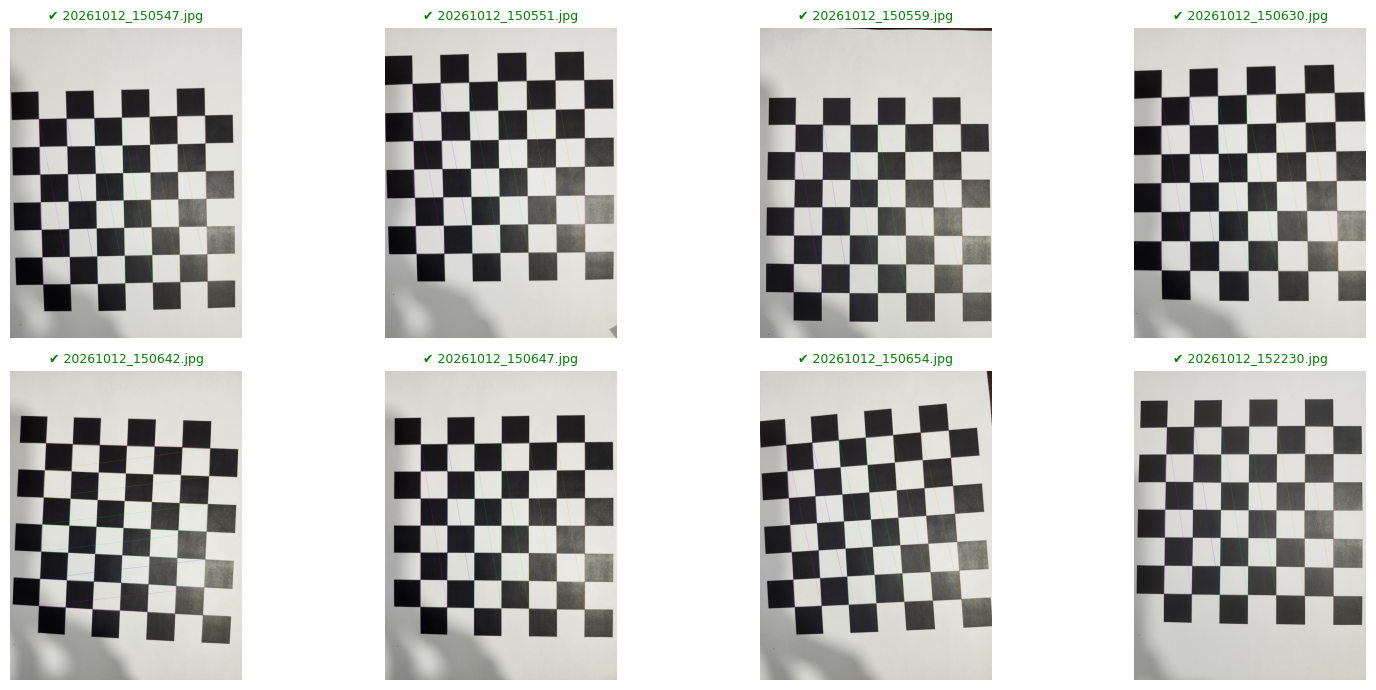

Detected board in 8/8 of the displayed images.


In [22]:


n_show = min(8, len(image_paths))
if n_show == 0:
    print("No images to show.")
else:
    cols = 4
    rows = (n_show + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
    axes = axes.flatten()

    for i in range(n_show):
        path = image_paths[i]
        img = cv2.imread(path)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        ret, corners = cv2.findChessboardCorners(
            gray,
            (CHESSBOARD_COLS, CHESSBOARD_ROWS),
            flags=cv2.CALIB_CB_ADAPTIVE_THRESH
                + cv2.CALIB_CB_NORMALIZE_IMAGE
        )

        if ret:
            corners = cv2.cornerSubPix(gray, corners, (11, 11),
                                       (-1, -1), criteria)
            vis = cv2.drawChessboardCorners(
                img.copy(),
                (CHESSBOARD_COLS, CHESSBOARD_ROWS),
                corners, ret
            )
            title_colour = "green"
            title = f"✔ {Path(path).name}"
        else:
            vis = img
            title_colour = "red"
            title = f"✘ {Path(path).name} — not found"

        axes[i].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        axes[i].set_title(title, fontsize=9, color=title_colour)
        axes[i].axis("off")

    # Hide any unused subplots
    for j in range(n_show, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

    # Also print a summary
    n_ok = sum(
        1 for p in image_paths[:n_show]
        if cv2.findChessboardCorners(
            cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2GRAY),
            (CHESSBOARD_COLS, CHESSBOARD_ROWS),
            flags=cv2.CALIB_CB_ADAPTIVE_THRESH
                + cv2.CALIB_CB_NORMALIZE_IMAGE
        )[0]
    )
    print(f"Detected board in {n_ok}/{n_show} of the displayed images.")

In [24]:
##############################################
# CALIBRATION
##############################################

ret, K, dist, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints, image_size, None, None
)

if not ret:
    raise RuntimeError("Calibration failed.")

print("=" * 60)
print("CALIBRATION RESULT")
print("=" * 60)

print(f"\nCamera matrix K (3x3):\n{K}\n")

fx = K[0, 0]
fy = K[1, 1]
cx = K[0, 2]
cy = K[1, 2]

print(f"fx = {fx:.3f} px")
print(f"fy = {fy:.3f} px")
print(f"cx = {cx:.3f} px  (principal point)")
print(f"cy = {cy:.3f} px")

print(f"\nDistortion coefficients (k1, k2, p1, p2, k3):")
print(f"  {dist.ravel()}")

# RMS reprojection error
mean_error = 0.0
per_image_errors = []
mean_error = 0.0
per_image_errors = []

for i in range(len(objpoints)):
    imgpoints_proj, _ = cv2.projectPoints(
        objpoints[i], rvecs[i], tvecs[i], K, dist
    )

    # Reshape both to (N, 2) so cv2.norm sees matching types.
    pts_actual = imgpoints[i].reshape(-1, 2).astype(np.float32)
    pts_proj   = imgpoints_proj.reshape(-1, 2).astype(np.float32)

    err = cv2.norm(pts_actual, pts_proj, cv2.NORM_L2) / len(pts_proj)
    per_image_errors.append(err)
    mean_error += err

mean_error /= len(objpoints)
per_image_errors = np.array(per_image_errors)

print(f"\nRMS reprojection error (calibrateCamera): {ret:.4f} px")
print(f"Mean per-image reprojection error:         {mean_error:.4f} px")
print(f"Min / Max per-image error:                 "
      f"{per_image_errors.min():.4f} / "
      f"{per_image_errors.max():.4f} px")

if ret < 1.0:
    print("\n✔ RMS < 1 px — good calibration.")
elif ret < 2.0:
    print("\n~ RMS between 1 and 2 px — acceptable but could be better.")
else:
    print("\n✘ RMS > 2 px — consider retaking photos with "
          "better lighting, sharper focus, and more varied poses.")

# Which images have the highest per-image error?
worst_idx = np.argsort(per_image_errors)[::-1][:5]
print("\nHighest-error images (candidates to drop):")
for idx in worst_idx:
    print(f"  {Path(good_paths[idx]).name:40s}  "
          f"{per_image_errors[idx]:.4f} px")

CALIBRATION RESULT

Camera matrix K (3x3):
[[2.84739619e+03 0.00000000e+00 1.52749454e+03]
 [0.00000000e+00 2.85081861e+03 2.00317535e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

fx = 2847.396 px
fy = 2850.819 px
cx = 1527.495 px  (principal point)
cy = 2003.175 px

Distortion coefficients (k1, k2, p1, p2, k3):
  [ 0.12992408 -0.43788245  0.00077377  0.00140555  0.39370364]

RMS reprojection error (calibrateCamera): 1.5964 px
Mean per-image reprojection error:         0.2272 px
Min / Max per-image error:                 0.1772 / 0.2804 px

~ RMS between 1 and 2 px — acceptable but could be better.

Highest-error images (candidates to drop):
  20261012_150630.jpg                       0.2804 px
  20261012_152705.jpg                       0.2704 px
  20261012_150551.jpg                       0.2510 px
  20261012_152230.jpg                       0.2410 px
  20261012_150654.jpg                       0.2374 px


In [25]:
##############################################
# CONVERTING FOCAL LENGTH FROM PIXELS TO MILLIMETRES
##############################################

img_width_px = image_size[0]
mm_per_pixel = SENSOR_WIDTH_MM / img_width_px

focal_px_avg = (fx + fy) / 2.0
focal_mm = focal_px_avg * mm_per_pixel

# Horizontal and vertical field of view (approximate, ignoring distortion)
fov_x_deg = 2 * np.degrees(np.arctan(img_width_px / (2 * fx)))
fov_y_deg = 2 * np.degrees(
    np.arctan(image_size[1] / (2 * fy))
)

print("=" * 60)
print("FOCAL LENGTH")
print("=" * 60)
print(f"Sensor width (spec)      : {SENSOR_WIDTH_MM} mm")
print(f"Image width              : {img_width_px} px")
print(f"mm per pixel             : {mm_per_pixel:.6f} mm/px")
print(f"\nfx = {fx:.2f} px   fy = {fy:.2f} px")
print(f"Focal length (avg)       : {focal_px_avg:.2f} px")
print(f"Focal length             : {focal_mm:.3f} mm")
print(f"\nApprox. horizontal FOV   : {fov_x_deg:.2f}°")
print(f"Approx. vertical FOV     : {fov_y_deg:.2f}°")

# Sanity check
if 2.5 <= focal_mm <= 12.0:
    print("\n✔ Focal length is in the typical range for a phone "
          "wide-angle lens.")
else:
    print("\n⚠ Focal length is unusual for a phone camera. "
          "Double-check your sensor spec, or your calibration "
          "may be off.")

FOCAL LENGTH
Sensor width (spec)      : 8.16 mm
Image width              : 3000 px
mm per pixel             : 0.002720 mm/px

fx = 2847.40 px   fy = 2850.82 px
Focal length (avg)       : 2849.11 px
Focal length             : 7.750 mm

Approx. horizontal FOV   : 55.56°
Approx. vertical FOV     : 70.10°

✔ Focal length is in the typical range for a phone wide-angle lens.


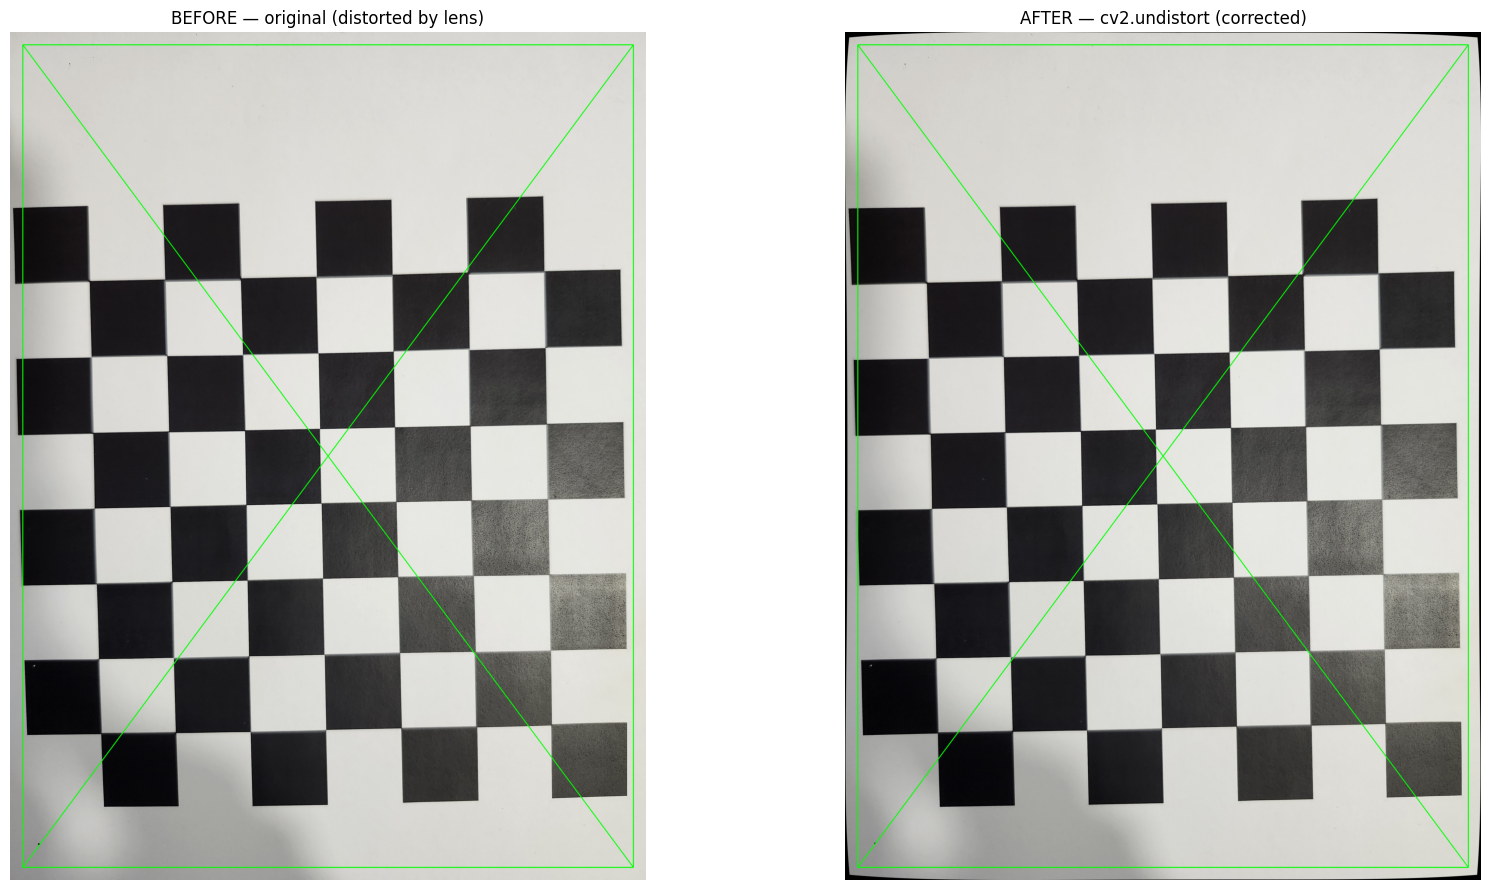

Demo image: 20261012_150547.jpg
Saved side-by-side to images/calibration_photos/undistort_before_after/undistort_before_after.png


In [30]:
##############################################
# UNDISTORT A DEMO IMAGE
##############################################


# Choose which image to undistort — index into good_paths
DEMO_INDEX = 0
demo_path = good_paths[DEMO_INDEX]
demo_img = cv2.imread(demo_path)

h, w = demo_img.shape[:2]

# OpenCV 5.x uses newImgSize (4.x used newSize).
# If you ever downgrade to 4.x, swap this back.
new_K, roi = cv2.getOptimalNewCameraMatrix(
    K, dist, (w, h), alpha=1, newImgSize=(w, h)
)

# The actual undistortion.
undistorted = cv2.undistort(demo_img, K, dist, None, new_K)

# Draw straight reference lines on both, so distortion is obvious
def draw_reference_lines(img):
    out = img.copy()
    h_, w_ = out.shape[:2]
    colour = (0, 255, 0)      # green in BGR
    thickness = max(2, w_ // 800)
    margin = int(min(h_, w_) * 0.02)

    cv2.rectangle(out, (margin, margin),
                  (w_ - margin, h_ - margin), colour, thickness)
    cv2.line(out, (margin, margin), (w_ - margin, h_ - margin),
             colour, thickness)
    cv2.line(out, (w_ - margin, margin), (margin, h_ - margin),
             colour, thickness)
    return out

before_vis = draw_reference_lines(demo_img)
after_vis  = draw_reference_lines(undistorted)

# Side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

axes[0].imshow(cv2.cvtColor(before_vis, cv2.COLOR_BGR2RGB))
axes[0].set_title("BEFORE — original (distorted by lens)", fontsize=12)
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(after_vis, cv2.COLOR_BGR2RGB))
axes[1].set_title("AFTER — cv2.undistort (corrected)", fontsize=12)
axes[1].axis("off")

plt.tight_layout()
plt.savefig("images/calibration_photos/undistort_before_after/undistort_before_after.png",
            dpi=140, bbox_inches="tight")
plt.show()

cv2.imwrite("images/calibration_photos/undistort_before_after/undistort_before.jpg", before_vis)
cv2.imwrite("images/calibration_photos/undistort_before_after/undistort_after.jpg",  after_vis)

print(f"Demo image: {Path(demo_path).name}")
print("Saved side-by-side to images/calibration_photos/undistort_before_after/undistort_before_after.png")

In [31]:
##############################################
# SAVE CALIBRATION FOR REUSE
##############################################

calib_file = Path("images/calibration.npz")
np.savez(
    calib_file,
    K=K,
    dist=dist,
    image_size=np.array(image_size),
    fx=fx, fy=fy, cx=cx, cy=cy,
    focal_mm=focal_mm,
    sensor_width_mm=SENSOR_WIDTH_MM,
    rms=ret,
)

print(f"Saved: {calib_file}")

# Example of loading it later:
#
# data = np.load("/content/calibration.npz")
# K = data["K"]; dist = data["dist"]
# und = cv2.undistort(img, K, dist)

Saved: images/calibration.npz


**Task 4. Augmented reality: a cube on the chessboard**

**Task 5. Depth from stereo**